<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/ex01_RNN_%EA%B8%B0%EC%B4%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 구글 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 작업 경로 변경
%cd "/content/drive/MyDrive/Colab Notebooks/딥러닝응용"
# cd = change directory

/content/drive/MyDrive/Colab Notebooks/딥러닝응용


In [ ]:
# 현재 경로 확인
!pwd

# print working directory

/content/drive/MyDrive/Colab Notebooks/딥러닝응용


In [ ]:
# 현재 디렉토리 목록 출력
!ls

# list

'ex01 RNN 기초.ipynb'


### 학습 목표
- RNN 알고리즘을 활용해서 시계열 데이터 분석해보자!
  - 시계열 데이터 : 텍스트데이터, 음성, 주식, 날씨 등 연속성이 있는 데이터
  - 이전 데이터가 다음 데이터에 영향을 주는 경우 활용 가능
- keras에서 제공하는 SimpleRNN을 사용해보자

### RNN(Recurrent Neural Network) 순환 신경망
- 앞서 입력받은 데이터의 연산 결과를 기억 -> 다음 연산에 사용해서 학습하는 방법
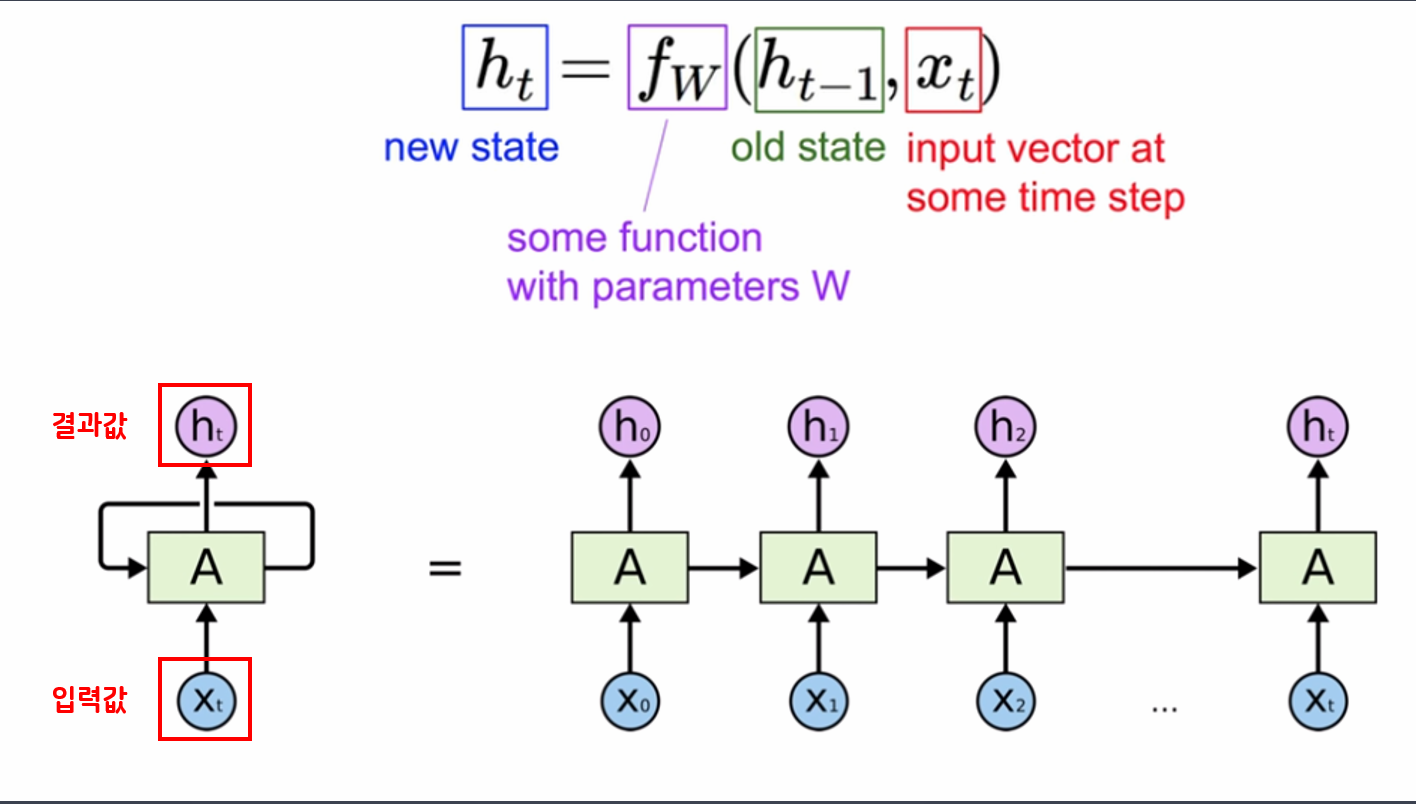


### 텍스트데이터 분석 전처리
- 토큰화 : 텍스트데이터를 특정 기준에 맞춰서 자르는 과정
  - 목적에 따라서 맞춰서 사용
- 수치화(벡터화) : 잘라진 토큰을 숫자로 변경하는 과정(컴퓨터가 학습할 수 있는 형태로 변경)
  - 원핫인코딩, BOW(Bag of Words), TF-IDF(단어 빈도에 따라서 가중치/패널티 부여)
  - 워드임베딩 -> 학습을 기반으로 수치화하는 방법

### 알파벳 한글자 단위로 학습하기
- 5개의 알파벳으로 구성된 단어를 학습
- 4개의 알파벳을 보고 다음 글자를 맞추는 모델 생성
- hello, apple, happy, drink, house
- 토큰화 : 알파벳 단위
- 수치화 : 원핫인코딩
- 단어 사전 : 모델이 학습을 위해 사용되는 단어 묶음
  - h, e, l, o, a, p, y, d, r, i, n, k, u, s(14개)

In [ ]:
# X = np.array([[h,e,l,l],
#                [a,p,p,l],
#                [h,a,p,p],
#                [d,r,i,n],
#                [h,o,u,s]])

# y = np.array([o, e, y, k, e])

In [ ]:
# 단어사전 만들기
# h, e, l, o, a, p, y, d, r, i, n, k, u, s (14개)
# [1,0,0,0,0,0,0,0,0,0,0,0,0,0] # h
# [0,1,0,0,0,0,0,0,0,0,0,0,0,0] # e
# [0,0,1,0,0,0,0,0,0,0,0,0,0,0] # l
# [0,0,0,1,0,0,0,0,0,0,0,0,0,0] # o
# [0,0,0,0,1,0,0,0,0,0,0,0,0,0] # a
# [0,0,0,0,0,1,0,0,0,0,0,0,0,0] # p
# [0,0,0,0,0,0,1,0,0,0,0,0,0,0] # y
# [0,0,0,0,0,0,0,1,0,0,0,0,0,0] # d
# [0,0,0,0,0,0,0,0,1,0,0,0,0,0] # r
# [0,0,0,0,0,0,0,0,0,1,0,0,0,0] # i
# [0,0,0,0,0,0,0,0,0,0,1,0,0,0] # n
# [0,0,0,0,0,0,0,0,0,0,0,1,0,0] # k
# [0,0,0,0,0,0,0,0,0,0,0,0,1,0] # u
# [0,0,0,0,0,0,0,0,0,0,0,0,0,1] # s

In [ ]:
import numpy as np

In [ ]:
# 같은 변수 한번에 수정하는 방법!!
# ctrl + shift + L

X = np.array([[[1,0,0,0,0,0,0,0,0,0,0,0,0,0],[0,1,0,0,0,0,0,0,0,0,0,0,0,0],[0,0,1,0,0,0,0,0,0,0,0,0,0,0],[0,0,1,0,0,0,0,0,0,0,0,0,0,0]],
               [[0,0,0,0,1,0,0,0,0,0,0,0,0,0],[0,0,0,0,0,1,0,0,0,0,0,0,0,0],[0,0,0,0,0,1,0,0,0,0,0,0,0,0],[0,0,1,0,0,0,0,0,0,0,0,0,0,0]],
               [[1,0,0,0,0,0,0,0,0,0,0,0,0,0],[0,0,0,0,1,0,0,0,0,0,0,0,0,0],[0,0,0,0,0,1,0,0,0,0,0,0,0,0],[0,0,0,0,0,1,0,0,0,0,0,0,0,0]],
               [[0,0,0,0,0,0,0,1,0,0,0,0,0,0],[0,0,0,0,0,0,0,0,1,0,0,0,0,0],[0,0,0,0,0,0,0,0,0,1,0,0,0,0],[0,0,0,0,0,0,0,0,0,0,1,0,0,0]],
               [[1,0,0,0,0,0,0,0,0,0,0,0,0,0],[0,0,0,1,0,0,0,0,0,0,0,0,0,0],[0,0,0,0,0,0,0,0,0,0,0,0,1,0],[0,0,0,0,0,0,0,0,0,0,0,0,0,1]]])
# h,e,l,l
# a,p,p,l
# h,a,p,p
# d,r,i,n
# h,o,u,s
X.shape

(5, 4, 14)

In [ ]:
# y데이터 o, e, y, k, e
y = np.array([
    [0,0,0,1,0,0,0,0,0,0,0,0,0,0], # o
    [0,1,0,0,0,0,0,0,0,0,0,0,0,0], # e
    [0,0,0,0,0,0,1,0,0,0,0,0,0,0], # y
    [0,0,0,0,0,0,0,0,0,0,0,1,0,0], # k
    [0,1,0,0,0,0,0,0,0,0,0,0,0,0]  # e
])
y.shape

(5, 14)

In [ ]:
X.shape, y.shape

# (5, 4, 14) : 문제데이터(X)
# 5 : 샘플의 개수
# 4 : 각 샘플의 글자 수
# 14 : 글자 사전의 문자 개수(각 글자는 14차원의 원핫 벡터로 표현)

# (5, 14) : 정답데이터(Y)
# 5 : 샘플의 개수
# 14 : 글자 사전의 문자 개수(각 글자는 14차원의 원핫 벡터로 표현)



((5, 4, 14), (5, 14))

In [ ]:
# 모델링 도구 불러오기
from tensorflow.keras import Sequential # 뼈대
from tensorflow.keras.layers import InputLayer, Dense, SimpleRNN # 입력층, 중간층/출력층 쌓는 도구, RNN층

# SimpleRNN : keras에서 제공하는 가장 기본적인 RNN 층

In [ ]:
# RNN 모델링

# 뼈대 구축
model = Sequential()

# 입력층
model.add(InputLayer(shape = (4, 14))) # 샘플 수를 제외한 입력 모양
# SimpleRNN은 시퀀스(시계열) 데이터를 처리하는 층(레이어)
# 입력 데이터는 3차원(shape은 2차원으로 설정)
# (배치 크기, 시퀀스 길이, 입력특성 차원)의 형태를 기대

# 중간층
model.add(SimpleRNN(units = 16)) # 활성화함수 기본값 tanh

# 출력층 -> 다중분류 -> 14개의 알파벳 중 1개
model.add(Dense(units = 14, activation = 'softmax'))

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 14)             │           238 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 734 (2.87 KB)

 Trainable params: 734 (2.87 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# simple_rnn : 496개의 학습가능한 파라미터
# 입력 노드 수(14) * 출력 노드 수(16) + (출력 노드 수(16) * 출력 노드 수(16)) + 편향 값(16) = 496

# dense : 238개의 학습 가능한 파라미터
# 입력 차원 16 * 출력 차원 14 + 편향 값 14 = 238

In [ ]:
# 학습 방법 및 평가 방법 설정
# loss : 다중분류, 최적하함수 : 'adam', 평가지표 : 정확도
model.compile(loss = 'categorical_crossentropy',
              optimizer = 'adam',
              metrics = ['accuracy']
              )

In [ ]:
# 모델 학습
model.fit(X, y, epochs = 1000)

Epoch 1/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.4000 - loss: 2.7085
Epoch 2/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.4000 - loss: 2.6823
Epoch 3/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.4000 - loss: 2.6562
Epoch 4/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.4000 - loss: 2.6303
Epoch 5/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.4000 - loss: 2.6044
Epoch 6/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.4000 - loss: 2.5787
Epoch 7/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.4000 - loss: 2.5532
Epoch 8/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.4000 - loss: 2.5277
Epoch 9/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.4000 - loss: 2.5025
Epoch 10/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.4000 - loss: 2.4773
Epoch 11/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.4000 - loss: 2.4523
Epoch 12/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0

In [ ]:
 # 학습한 모델로 예측해보기
 X[0].shape

(4, 14)

In [ ]:
test = X[0].reshape(1, 4, 14) # 3차원으로 형 변환

# SimpleRNN이 입력받는 데이터 3차원

In [ ]:
model.predict(test).argmax()

#   h, e, l, o, a, p, y, d, r, i, n, k, u, s(14개)
# 1번 인덱스 값일 확률이 가장 높다

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


np.int64(3)